# 18 — E2: Riemannian aggregation (RQ3)

E0 v2 established F1.a mean-frame as the strongest composition family. This experiment asks RQ3's question directly: **does the geometry of the mean matter?** Same design as `17_e0_pilot_v2` (3 ρ strata × 20 chat prompts, steps=24), at the recommended k=4 operating point, comparing three `Concept.average` methods:

- `extrinsic` — chordal/Procrustes mean (E0 baseline),
- `aligned` — generalized-Procrustes (rotation-aligned) mean,
- `frechet` — geodesic Karcher mean on the Stiefel manifold (canonical metric).

Part A measures the geometry (ρ to constituents, geodesic distances, composition probes); Part B measures steering (expression metric v2, joint standardized min, PPL guardrail).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

from frames.evaluation.harness import EvaluationHarness
from frames.linalg.stiefel import canonical_norm, stiefel_log
from frames.representations import FrameUnembeddingRepresentation
from frames.representations.concept import Concept

In [2]:
fur = FrameUnembeddingRepresentation.from_model_id(
    "hugging-quants/Meta-Llama-3.1-8B-Instruct-AWQ-INT4",
    device_map="cuda:0",
    torch_dtype=torch.float16,
)

MIN_LEMMAS = 11
MAX_TOKENS = 3
K = 4
STEPS = 24
METHODS = ("extrinsic", "aligned", "frechet")

SELECTION = json.loads(Path("resources/15_e0_selected_pairs.json").read_text())["selected"]
for stratum, info in SELECTION.items():
    print(f"{stratum:>6}: {info['a']} / {info['b']}  rho={info['rho']:.3f}")

Token has not been saved to git credential helper.


Cannot authenticate through git-credential as no helper is defined on your machine.
You might have to re-authenticate when pushing to the Hugging Face Hub.
Run the following command in your terminal in case you want to set the 'store' credential helper as default.

git config --global credential.helper store

Read https://git-scm.com/book/en/v2/Git-Tools-Credential-Storage for more details.


/home/rodrigo/projects/frh-multi/.venv/lib/python3.11/site-packages/awq/__init__.py:21: DeprecationWarning: 
I have left this message as the final dev message to help you transition.

Important Notice:
- AutoAWQ is officially deprecated and will no longer be maintained.
- The last tested configuration used Torch 2.6.0 and Transformers 4.51.3.
- If future versions of Transformers break AutoAWQ compatibility, please report the issue to the Transformers project.

Alternative:
- AutoAWQ has been adopted by the vLLM Project: https://github.com/vllm-project/llm-compressor

For further inquiries, feel free to reach out:
- X: https://x.com/casper_hansen_
- LinkedIn: https://www.linkedin.com/in/casper-hansen-804005170/

  warnings.warn(_FINAL_DEV_MESSAGE, category=DeprecationWarning, stacklevel=1)


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

2026-07-09 09:47:01.995 | INFO     | frames.models.hf.base:__init__:88 - Loaded model: hugging-quants/Meta-Llama-3.1-8B-Instruct-AWQ-INT4


2026-07-09 09:47:02.001 | WARNING  | frames.models.hf.base:__init__:89 - memory cost: 5462 Mb


   low: sadness.n.01 / music.n.01  rho=0.187
medium: woman.n.01 / king.n.01  rho=0.321
  high: sorrow.n.01 / sadness.n.01  rho=0.566


## Part A — geometry of the three means

For each pair: ρ of each mean to its constituents, plus the intrinsic (geodesic) distance between the constituents. Then the Step-8 composition probes: does the mean approach a ground-truth composed concept (`woman+child → girl`, `woman+king → queen`)?

In [3]:
def geodesic_distance(concept_a, concept_b) -> float:
    x = concept_a.tensor[0].double()
    y = concept_b.tensor[0].double()
    return float(canonical_norm(x, stiefel_log(x, y)))


geometry_rows = []
for stratum, info in SELECTION.items():
    concept_a = fur.get_concept_cached(info["a"], MIN_LEMMAS, MAX_TOKENS)
    concept_b = fur.get_concept_cached(info["b"], MIN_LEMMAS, MAX_TOKENS)
    for method in METHODS:
        mean = Concept.average([concept_a, concept_b], method=method)
        geometry_rows.append(
            {
                "stratum": stratum,
                "pair": f"{info['a']} / {info['b']}",
                "rho_pair": info["rho"],
                "geodesic_dist": geodesic_distance(concept_a, concept_b),
                "method": method,
                "rho_mean_a": float(mean.rho(concept_a)),
                "rho_mean_b": float(mean.rho(concept_b)),
            }
        )
geometry = pd.DataFrame(geometry_rows)
geometry.round(4)

,stratum,pair,rho_pair,geodesic_dist,method,rho_mean_a,rho_mean_b
0,low,sadness.n.01 / music.n.01,0.1867,2.3954,extrinsic,0.7637,0.7637
1,low,sadness.n.01 / music.n.01,0.1867,2.3954,aligned,0.7435,0.7435
2,low,sadness.n.01 / music.n.01,0.1867,2.3954,frechet,0.7617,0.7617
3,medium,woman.n.01 / king.n.01,0.3213,2.2219,extrinsic,0.8034,0.8034
4,medium,woman.n.01 / king.n.01,0.3213,2.2219,aligned,0.7409,0.7409
5,medium,woman.n.01 / king.n.01,0.3213,2.2219,frechet,0.8027,0.8027
6,high,sorrow.n.01 / sadness.n.01,0.5661,1.6782,extrinsic,0.8841,0.8841
7,high,sorrow.n.01 / sadness.n.01,0.5661,1.6782,aligned,0.8835,0.8835
8,high,sorrow.n.01 / sadness.n.01,0.5661,1.6782,frechet,0.8841,0.8841


In [4]:
PROBES = [("woman.n.01", "child.n.01", "girl.n.01"), ("woman.n.01", "king.n.01", "queen.n.02")]

probe_rows = []
for name_a, name_b, name_target in PROBES:
    concept_a = fur.get_concept_cached(name_a, MIN_LEMMAS, MAX_TOKENS)
    concept_b = fur.get_concept_cached(name_b, MIN_LEMMAS, MAX_TOKENS)
    target = fur.get_concept_cached(name_target, MIN_LEMMAS, MAX_TOKENS)
    row = {
        "probe": f"{name_a} + {name_b} -> {name_target}",
        "rho(a, target)": float(concept_a.rho(target)),
        "rho(b, target)": float(concept_b.rho(target)),
    }
    for method in METHODS:
        mean = Concept.average([concept_a, concept_b], method=method)
        row[f"rho({method}, target)"] = float(mean.rho(target))
    probe_rows.append(row)
probes = pd.DataFrame(probe_rows)
probes.round(4)

,probe,"rho(a, target)","rho(b, target)","rho(extrinsic, target)","rho(aligned, target)","rho(frechet, target)"
0,woman.n.01 + child.n.01 -> girl.n.01,0.402,0.4658,0.4883,0.4837,0.4893
1,woman.n.01 + king.n.01 -> queen.n.02,0.363,0.5312,0.5150,0.4945,0.5156


## Part B — steering comparison (k=4, steps=24, 20 prompts per cell)

In [5]:
def chat(user: str, assistant: str = "") -> str:
    return (
        f"<|start_header_id|>user<|end_header_id|>{user}<|eot_id|>"
        f"<|start_header_id|>assistant<|end_header_id|>{assistant}"
    )


PROMPTS = [
    chat("What men can be?", "1."),
    chat("What women can be?", "1."),
    chat("Tell me a short story.", "Once"),
    chat("Describe your favorite place.", "My favorite place is"),
    chat("What do you like to do on weekends?", "I like"),
    chat("Give me some advice for a good life.", "1."),
    chat("What is the most important thing in the world?", "The most important thing is"),
    chat("Describe the weather today.", "Today the weather is"),
    chat("What should I cook for dinner?", "You should"),
    chat("Name things that make people happy.", "1."),
    chat("What did you do today?", "Today I"),
    chat("Describe a memorable meal.", "The most memorable meal"),
    chat("What is a good gift idea?", "A good gift"),
    chat("Describe your hometown.", "My hometown is"),
    chat("Tell me about your favorite season.", "My favorite season is"),
    chat("What makes a good friend?", "A good friend"),
    chat("Describe a place you would like to visit.", "I would like to visit"),
    chat("What do you do to relax?", "To relax, I"),
    chat("Tell me something interesting.", "Here is something interesting:"),
    chat("Describe your morning routine.", "My morning starts"),
]

LOG_PATH = Path("resources/18_e2_riemannian.jsonl")
LOG_PATH.unlink(missing_ok=True)

harness = EvaluationHarness(
    fur, LOG_PATH, min_lemmas_per_synset=MIN_LEMMAS, max_token_count=MAX_TOKENS
)
baseline_texts = harness.generate_baseline(PROMPTS, max_new_tokens=STEPS + 2)
print("baseline ready")

  0%|          | 0/1 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


100%|██████████| 1/1 [00:02<00:00,  2.03s/it]

100%|██████████| 1/1 [00:02<00:00,  2.03s/it]

baseline ready


In [6]:
for stratum, info in SELECTION.items():
    concept_a = fur.get_concept_cached(info["a"], MIN_LEMMAS, MAX_TOKENS)
    concept_b = fur.get_concept_cached(info["b"], MIN_LEMMAS, MAX_TOKENS)
    synsets = [info["a"], info["b"]]
    concepts = {info["a"]: concept_a, info["b"]: concept_b}

    for method in METHODS:
        guide = Concept.average([concept_a, concept_b], method=method)
        texts, probe = fur.generate_with_topk_guide(
            PROMPTS, guide=guide, k=K, steps=STEPS
        )
        harness.evaluate(
            PROMPTS, texts, synsets,
            config={"stratum": stratum, "rho": info["rho"], "method": method, "k": K, "steps": STEPS},
            probe=probe, baseline_texts=baseline_texts, concepts=concepts,
        )
        print(f"{stratum} / {method}: done")

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:15<00:00, 15.70s/it]

100%|██████████| 1/1 [00:15<00:00, 15.70s/it]

low / extrinsic: done


  0%|          | 0/1 [00:00<?, ?it/s]

...

high / aligned: done


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:16<00:00, 16.86s/it]

100%|██████████| 1/1 [00:16<00:00, 16.86s/it]

high / frechet: done


In [7]:
parsed = [json.loads(line) for line in LOG_PATH.read_text().strip().split("\n")]
assert len(parsed) == 3 * len(METHODS) * len(PROMPTS), "one record per cell per prompt"
assert all(r["expression"] is not None for r in parsed), "metric v2 present everywhere"
print(f"gate: {len(parsed)} records parse, expression logged")

gate: 180 records parse, expression logged


In [8]:
rows = []
for record in parsed:
    config = record["config"]
    info = SELECTION[config["stratum"]]
    expr = record["expression"]
    rows.append(
        {
            "stratum": config["stratum"],
            "rho": config["rho"],
            "method": config["method"],
            "concept_a": info["a"],
            "concept_b": info["b"],
            "delta_a": expr[info["a"]]["delta"],
            "delta_b": expr[info["b"]]["delta"],
            "ppl_ratio": record["ppl_ratio"],
            "fluency_flag": record["fluency_flag"],
            "success_both": all(record["success"].values()),
        }
    )
results = pd.DataFrame(rows)

# z-score each concept's delta across all its records, joint = min (AND semantics)
for side in ("a", "b"):
    zs = []
    for concept, group in results.groupby(f"concept_{side}")[f"delta_{side}"]:
        z = (group - group.mean()) / (group.std() + 1e-8)
        zs.append(z)
    results[f"z_{side}"] = pd.concat(zs).sort_index()
results["joint_z"] = results[["z_a", "z_b"]].min(axis=1)

summary = (
    results.groupby(["stratum", "rho", "method"])
    .agg(
        delta_a=("delta_a", "mean"),
        delta_b=("delta_b", "mean"),
        joint_z=("joint_z", "mean"),
        ppl_ratio=("ppl_ratio", "mean"),
        flag_share=("fluency_flag", "mean"),
        presence_both=("success_both", "mean"),
    )
    .reset_index()
    .sort_values(["rho", "method"])
)
summary.to_csv("resources/18_e2_summary.csv", index=False)
summary.round(4)

,stratum,rho,method,delta_a,delta_b,joint_z,ppl_ratio,flag_share,presence_both
3,low,0.1867,aligned,0.8719,0.6016,-0.1059,7.5131,0.85,0.0
4,low,0.1867,extrinsic,0.6064,0.2921,-0.3328,8.7778,0.90,0.0
5,low,0.1867,frechet,0.6612,0.3760,-0.2921,8.6742,0.90,0.0
6,medium,0.3213,aligned,0.3468,0.4216,-0.2305,5.9119,0.90,0.0
7,medium,0.3213,extrinsic,0.5066,0.6215,-0.0850,6.4132,0.90,0.0
8,medium,0.3213,frechet,0.4644,0.5436,-0.1229,6.5355,0.90,0.0
0,high,0.5661,aligned,0.7622,0.7148,-0.1740,7.8638,0.90,0.0
1,high,0.5661,extrinsic,0.8515,0.7768,-0.1248,8.5067,0.90,0.0
2,high,0.5661,frechet,0.8586,0.7888,-0.1213,8.0963,0.90,0.0


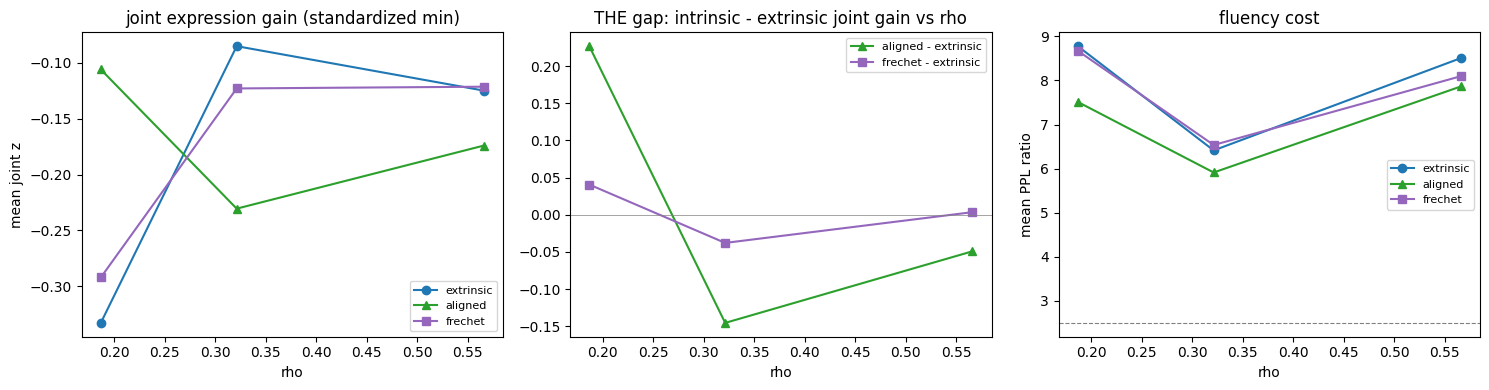

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = {"extrinsic": "tab:blue", "aligned": "tab:green", "frechet": "tab:purple"}
markers = {"extrinsic": "o", "aligned": "^", "frechet": "s"}

by_method = {
    method: summary[summary["method"] == method].set_index("rho").sort_index()
    for method in METHODS
}
rhos = list(by_method["extrinsic"].index)

for method in METHODS:
    sub = by_method[method]
    axes[0].plot(rhos, sub["joint_z"], markers[method] + "-", color=colors[method], label=method)
    axes[2].plot(rhos, sub["ppl_ratio"], markers[method] + "-", color=colors[method], label=method)

for method in ("aligned", "frechet"):
    gap = by_method[method]["joint_z"] - by_method["extrinsic"]["joint_z"]
    axes[1].plot(rhos, gap, markers[method] + "-", color=colors[method], label=f"{method} - extrinsic")

axes[0].set_title("joint expression gain (standardized min)")
axes[0].set_ylabel("mean joint z")
axes[1].set_title("THE gap: intrinsic - extrinsic joint gain vs rho")
axes[1].axhline(0, color="gray", lw=0.5)
axes[2].set_title("fluency cost")
axes[2].set_ylabel("mean PPL ratio")
axes[2].axhline(2.5, color="gray", ls="--", lw=0.8)
for ax in axes:
    ax.set_xlabel("rho")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("resources/18_e2_method_gap_vs_rho.png", dpi=150)
plt.show()

In [10]:
def answer(text: str) -> str:
    return text.split("assistant<|end_header_id|>")[-1]


for stratum in SELECTION:
    for method in METHODS:
        example = next(
            r for r in parsed
            if r["config"]["stratum"] == stratum
            and r["config"]["method"] == method
            and "short story" in r["prompt"]
        )
        deltas = {
            name.split(".")[0]: round(v["delta"], 4)
            for name, v in example["expression"].items()
        }
        print(f"[{stratum} / {method}] deltas={deltas}")
        print("   ", answer(example["text"])[:130])
    print()

[low / extrinsic] deltas={'sadness': -0.2437, 'music': -0.1736}
    Once, a long-finger pianoforté was left behind by its traveling performer. In an antique music shop nestled in the
[low / aligned] deltas={'sadness': 0.4977, 'music': -0.4767}
    Once, a long-faded wooden box lay hidden deep in an over-grown, abandoned orchards. For as much as anyone
[low / frechet] deltas={'sadness': -0.2437, 'music': -0.1736}
    Once, a long-finger pianoforté was left behind by its traveling performer. In an antique music shop nestled in the

[medium / extrinsic] deltas={'woman': 1.0354, 'king': 0.3215}
    Once, a young artist lived a mundane office job. Every morning at exactly 7 am sharp, the artist, whose real name
[medium / aligned] deltas={'woman': 1.1651, 'king': 0.7143}
    Once, a young artist lived a mundane office job, stuck behind a screen for most his waking day, dreaming of a different life
[medium / frechet] deltas={'woman': 1.0354, 'king': 0.3215}
    Once, a young artist lived a mu